In [1]:
import sys
print(sys.executable)

C:\Users\sneha\anaconda3\envs\object_detection\python.exe


In [2]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [3]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: []


In [4]:
import os

import numpy as np
import matplotlib.pyplot as plt
import PIL.Image, PIL.ImageFont, PIL.ImageDraw

import tensorflow as tf
import tensorflow_datasets as tfds

In [5]:
print("Hello")

Hello


In [6]:
import os

import numpy as np
import matplotlib.pyplot as plt

import PIL.Image, PIL.ImageFont, PIL.ImageDraw

import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("TFDS:", tfds.__version__)
print("Everything is working!")

NumPy: 2.4.6
TensorFlow: 2.21.0
TFDS: 4.9.10
Everything is working!


In [7]:
print("Hello")

Hello


In [8]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [9]:
import os

import numpy as np
import matplotlib.pyplot as plt

import PIL.Image, PIL.ImageFont, PIL.ImageDraw

import tensorflow as tf

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Everything is working!")

NumPy: 2.4.6
TensorFlow: 2.21.0
Everything is working!


In [10]:
import numpy as np
print(np.__version__)
print(np.__file__)

2.4.6
C:\Users\sneha\anaconda3\envs\object_detection\Lib\site-packages\numpy\__init__.py


In [11]:
im_width = 75
im_height = 75
use_normalized_coordinates = True

In [12]:
def draw_bounding_boxes_on_image_array(image, boxes, color=[], thickness=1, display_str_list=()):
    image_pil = PIL.Image.fromarray(image)
    rgbimg = PIL.Image.new("RGBA", image_pil.size)
    rgbimg.paste(image_pil)
    draw_bounding_boxes_on_image(rgbimg, boxes, color, thickness, display_str_list)
    return np.array(rgbimg)

In [13]:
def draw_bounding_boxes_on_image(image, boxes, color=[], thickness=1, display_str_list=()):
    boxes_shape = boxes.shape
    if not boxes_shape:
        return
    if len(boxes_shape) != 2 or boxes_shape[1] != 4:
        raise ValueError('Input must be of size [N,4]')
    for i in range(boxes_shape[0]):
        draw_bounding_box_on_image(
            image,
            boxes[i,1],
            boxes[i,0],
            boxes[i,3],
            boxes[i,2],
            color[i],
            thickness,
            display_str_list[i]
        )

In [14]:
def draw_bounding_box_on_image(image, ymin, xmin, ymax, xmax,
                               color='red', thickness=1,
                               display_str_list=None,
                               use_normalized_coordinates=True):
    draw = PIL.ImageDraw.Draw(image)
    im_width, im_height = image.size

    if use_normalized_coordinates:
        (left, right, top, bottom) = (
            xmin * im_width,
            xmax * im_width,
            ymin * im_height,
            ymax * im_height
        )
    else:
        (left, right, top, bottom) = (xmin, xmax, ymin, ymax)
    draw.line(
        [(left, top), (left, bottom),
         (right, bottom), (right, top),
         (left, top)],
        width=thickness,
        fill=color
    )
        

In [15]:
def dataset_to_numpy_util(training_dataset, validation_dataset, N):
    batch_train_ds = training_dataset.unbatch().batch(N)

    if tf.executing_eagerly():

        for validation_digits, (validation_labels, validation_bboxes) in validation_dataset:
            validation_digits = validation_digits.numpy()
            validation_labels = validation_labels.numpy()
            validation_bboxes = validation_bboxes.numpy()
            break

        for training_digits, (training_labels, training_bboxes) in training_dataset:
            training_digits = training_digits.numpy()
            training_labels = training_labels.numpy()
            training_bboxes = training_bboxes.numpy()
            break

    validation_labels = np.argmax(validation_labels, axis=1)
    training_labels = np.argmax(training_labels, axis=1)

    return (
        training_digits,
        training_labels,
        training_bboxes,
        validation_digits,
        validation_labels,
        validation_bboxes,
    )

In [16]:
MATPLOTLIB_FONT_DIR = os.path.join(
    os.path.dirname(plt.__file__),
    "mpl-data/fonts/ttf"
)


def create_digits_from_local_fonts(n):
    font_labels = []

    img = PIL.Image.new('LA', (75 * n, 75), color=(0, 255))

    font1 = PIL.ImageFont.truetype(
        os.path.join(MATPLOTLIB_FONT_DIR, 'DejaVuSansMono-Oblique.ttf'),
        25
    )

    font2 = PIL.ImageFont.truetype(
        os.path.join(MATPLOTLIB_FONT_DIR, 'STIXGeneral.ttf'),
        25
    )

    d = PIL.ImageDraw.Draw(img)

    for i in range(n):
        font_labels.append(i % 10)
        d.text(
            (7 + i * 75, 0 if i < 10 else -4),
            str(i % 10),
            fill=(255, 255),
            font=font1 if i < 10 else font2
        )

    font_digits = np.array(img.getdata(), np.float32)[:, 0] / 255.0

    font_digits = np.reshape(
        np.stack(
            np.split(
                np.reshape(font_digits, [75, 75 * n]),
                n,
                axis=1
            ),
            axis=0
        ),
        [n, 75 * 75]
    )

    return font_digits, font_labels


In [17]:
# Location of matplotlib fonts
MATPLOTLIB_FONT_DIR = os.path.join(
    os.path.dirname(plt.__file__),
    "mpl-data",
    "fonts",
    "ttf"
)


def create_digits_from_local_fonts(n):

    font_labels = []

    img = PIL.Image.new("LA", (75 * n, 75), color=(0, 255))

    font1 = PIL.ImageFont.truetype(
        os.path.join(MATPLOTLIB_FONT_DIR, "DejaVuSansMono-Oblique.ttf"),
        25,
    )

    font2 = PIL.ImageFont.truetype(
        os.path.join(MATPLOTLIB_FONT_DIR, "STIXGeneral.ttf"),
        25,
    )

    d = PIL.ImageDraw.Draw(img)

    for i in range(n):
        font_labels.append(i % 10)

        d.text(
            (7 + i * 75, 0 if i < 10 else -4),
            str(i % 10),
            fill=(255, 255),
            font=font1 if i < 10 else font2,
        )

    font_digits = np.array(img.getdata(), np.float32)[:, 0] / 255.0

    font_digits = np.reshape(
        np.stack(
            np.split(
                np.reshape(font_digits, [75, 75 * n]),
                n,
                axis=1,
            ),
            axis=0,
        ),
        [n, 75 * 75],
    )

    return font_digits, font_labels


def display_digits_with_boxes(
    digits,
    predictions,
    labels,
    pred_bboxes,
    bboxes,
    iou,
    title,
):

    n = min(10, len(predictions))

    indexes = np.random.choice(len(predictions), size=n, replace=False)

    n_digits = digits[indexes]
    n_predictions = predictions[indexes]
    n_labels = labels[indexes]

    n_iou = []
    if len(iou) > 0:
        n_iou = iou[indexes]

    n_pred_bboxes = []
    if len(pred_bboxes) > 0:
        n_pred_bboxes = pred_bboxes[indexes]

    n_bboxes = []
    if len(bboxes) > 0:
        n_bboxes = bboxes[indexes]

    n_digits = n_digits * 255.0
    n_digits = n_digits.reshape(n, 75, 75)

    fig = plt.figure(figsize=(20, 4))

    plt.title(title)
    plt.xticks([])
    plt.yticks([])

    iou_threshold = 0.6

    for i in range(n):

        ax = fig.add_subplot(1, n, i + 1)

        bboxes_to_plot = []

        if len(n_pred_bboxes) > 0:
            bboxes_to_plot.append(n_pred_bboxes[i])

        if len(n_bboxes) > 0:
            bboxes_to_plot.append(n_bboxes[i])

        img_to_draw = draw_bounding_boxes_on_image_array(
            image=n_digits[i],
            boxes=np.asarray(bboxes_to_plot),
            color=["red", "green"],
            display_str_list=["True", "Pred"],
        )

        ax.set_xlabel(str(n_predictions[i]))
        ax.set_xticks([])
        ax.set_yticks([])

        if n_predictions[i] != n_labels[i]:
            ax.xaxis.label.set_color("red")

        ax.imshow(img_to_draw, cmap="gray")

        if len(n_iou) > i:

            color = "black"

            if n_iou[i][0] < iou_threshold:
                color = "red"

            ax.text(
                0.2,
                -0.30,
                "iou: %.2f" % n_iou[i][0],
                color=color,
                transform=ax.transAxes,
            )

    plt.show()


def plot_metrics(metric_name, title):

    plt.figure(figsize=(8, 5))

    plt.title(title)

    plt.plot(
        history.history[metric_name],
        color="blue",
        label=metric_name,
    )

    plt.plot(
        history.history["val_" + metric_name],
        color="green",
        label="val_" + metric_name,
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric_name)

    plt.legend()

    plt.grid(True)

    plt.show()

In [18]:
strategy = tf.distribute.get_strategy()
strategy.num_replicas_in_sync

1

In [19]:
BATCH_SIZE = 64 * strategy.num_replicas_in_sync

In [20]:
import tensorflow_datasets as tfds

In [21]:
strategy = tf.distribute.get_strategy()
print(strategy.num_replicas_in_sync)

1


In [22]:
BATCH_SIZE = 64 * strategy.num_replicas_in_sync


In [23]:
def read_image_tfds(image, label):
    xmin = tf.random.uniform((), 0, 48, dtype=tf.int32)
    ymin = tf.random.uniform((), 0, 48, dtype=tf.int32)

    image = tf.reshape(image, (28, 28, 1))
    image = tf.image.pad_to_bounding_box(image, ymin, xmin, 75, 75)
    image = tf.cast(image, tf.float32) / 255.0

    xmin = tf.cast(xmin, tf.float32)
    ymin = tf.cast(ymin, tf.float32)

    xmax = (xmin + 28) / 75
    ymax = (ymin + 28) / 75

    xmin = xmin / 75
    ymin = ymin / 75

    return image, (tf.one_hot(label, 10), [xmin, ymin, xmax, ymax])


def get_training_dataset():

    with strategy.scope():
        dataset = tfds.load(
            "mnist",
            split="train",
            as_supervised=True,
            try_gcs=True
        )

        dataset = dataset.map(
            read_image_tfds,
            num_parallel_calls=tf.data.AUTOTUNE
        )

        dataset = dataset.shuffle(5000, reshuffle_each_iteration=True)
        dataset = dataset.repeat()
        dataset = dataset.batch(BATCH_SIZE, drop_remainder=True)
        dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


def get_validation_dataset():

    with strategy.scope():
        dataset = tfds.load(
            "mnist",
            split="train",
            as_supervised=True,
            try_gcs=True
        )

        dataset = dataset.map(
            read_image_tfds,
            num_parallel_calls=tf.data.AUTOTUNE
        )

        dataset = dataset.batch(10000, drop_remainder=True)
        dataset = dataset.repeat()

    return dataset


with strategy.scope():
    training_dataset = get_training_dataset()
    validation_dataset = get_validation_dataset()

In [24]:
(training_digits, training_labels, training_bboxes,
 validation_digits, validation_labels, validation_bboxes) = \
    dataset_to_numpy_util(training_dataset, validation_dataset, 10)

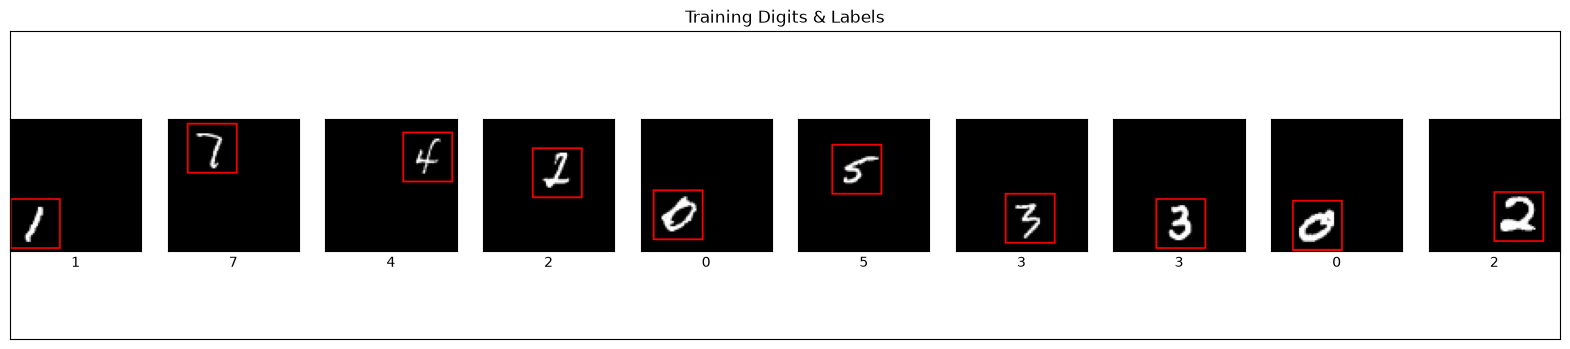

In [25]:
display_digits_with_boxes(
    training_digits,
    training_labels,
    training_labels,
    np.array([]),
    training_bboxes,
    np.array([]),
    "Training Digits & Labels"
)

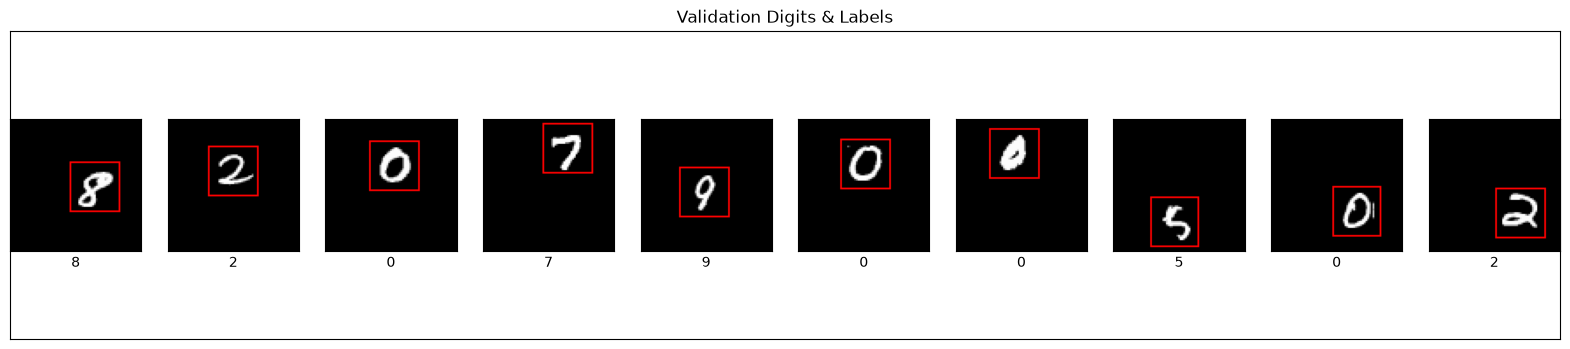

In [26]:
display_digits_with_boxes(
    validation_digits,
    validation_labels,
    validation_labels,
    np.array([]),
    validation_bboxes,
    np.array([]),
    "Validation Digits & Labels"
)

In [27]:
def feature_extractor(inputs):

    x = tf.keras.layers.Conv2D(
        16,
        kernel_size=3,
        activation="relu"
    )(inputs)

    x = tf.keras.layers.AveragePooling2D((2, 2))(x)

    x = tf.keras.layers.Conv2D(
        32,
        kernel_size=3,
        activation="relu"
    )(x)

    x = tf.keras.layers.AveragePooling2D((2, 2))(x)

    x = tf.keras.layers.Conv2D(
        64,
        kernel_size=3,
        activation="relu"
    )(x)

    x = tf.keras.layers.AveragePooling2D((2, 2))(x)

    return x

In [28]:
def dense_layers(inputs):

    x = tf.keras.layers.Flatten()(inputs)

    x = tf.keras.layers.Dense(
        128,
        activation="relu"
    )(x)

    return x

In [29]:
def classifier(inputs):

    classification_output = tf.keras.layers.Dense(
        10,
        activation="softmax",
        name="classification"
    )(inputs)

    return classification_output

In [30]:
def bounding_box_regression(inputs):

    bounding_box_regression_output = tf.keras.layers.Dense(
        4,
        name="bounding_box"
    )(inputs)

    return bounding_box_regression_output

In [31]:
def final_model(inputs):

    feature_cnn = feature_extractor(inputs)

    dense_output = dense_layers(feature_cnn)

    classification_output = classifier(dense_output)

    bounding_box_output = bounding_box_regression(dense_output)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=[
            classification_output,
            bounding_box_output
        ]
    )

    return model

In [32]:
def define_and_compile_model(inputs):

    model = final_model(inputs)

    model.compile(
        optimizer="adam",
        loss={
            "classification": "categorical_crossentropy",
            "bounding_box": "mse"
        },
        metrics={
            "classification": "accuracy",
            "bounding_box": "mse"
        }
    )

    return model

In [33]:
with strategy.scope():

    inputs = tf.keras.layers.Input(
        shape=(75, 75, 1)
    )

    model = define_and_compile_model(inputs)

In [34]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)       ┃ Output Shape     ┃   Param # ┃ Connected to     ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ input_layer        │ (None, 75, 75,   │         0 │ -                │
│ (InputLayer)       │ 1)               │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ conv2d (Conv2D)    │ (None, 73, 73,   │       160 │ input_layer[0][… │
│                    │ 16)              │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ average_pooling2d  │ (None, 36, 36,   │         0 │ conv2d[0][0]     │
│ (AveragePooling2D) │ 16)              │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ conv2d_1 (Conv2D)  │ (None, 34, 34,   │     4,640 │ average_pooling… │
│                    │ 32)              │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ average_pooling2d… │ (None, 17, 17,   │         0 │ conv2d_1[0][0]   │
│ (AveragePooling2D) │ 32)              │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ conv2d_2 (Conv2D)  │ (None, 15, 15,   │    18,496 │ average_pooling… │
│                    │ 64)              │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ average_pooling2d… │ (None, 7, 7, 64) │         0 │ conv2d_2[0][0]   │
│ (AveragePooling2D) │                  │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ flatten (Flatten)  │ (None, 3136)     │         0 │ average_pooling… │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ dense (Dense)      │ (None, 128)      │   401,536 │ flatten[0][0]    │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ classification     │ (None, 10)       │     1,290 │ dense[0][0]      │
│ (Dense)            │                  │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ bounding_box       │ (None, 4)        │       516 │ dense[0][0]      │
│ (Dense)            │                  │           │                  │
└────────────────────┴──────────────────┴───────────┴──────────────────┘

 Total params: 426,638 (1.63 MB)

 Trainable params: 426,638 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
tf.config.list_physical_devices("GPU")

[]

In [36]:
EPOCHS = 20

steps_per_epoch = 60000 // BATCH_SIZE

print("\n-----------------------------------")
print("Training the model...")
print("-----------------------------------\n")

history = model.fit(
    training_dataset,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_dataset,
    validation_steps=1,
    epochs=EPOCHS
)

loss, classification_loss, bounding_box_loss, classification_acc, bounding_box_mse = model.evaluate(
    validation_dataset,
    steps=1
)

print("\n-----------------------------------")
print("Validation Accuracy:", classification_acc)
print("-----------------------------------\n")


-----------------------------------
Training the model...
-----------------------------------

Epoch 1/20


C:\Users\sneha\anaconda3\envs\object_detection\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


937/937 ━━━━━━━━━━━━━━━━━━━━ 28s 28ms/step - bounding_box_loss: 0.0183 - bounding_box_mse: 0.0183 - classification_accuracy: 0.7018 - classification_loss: 0.8676 - loss: 0.8859 - val_bounding_box_loss: 0.0105 - val_bounding_box_mse: 0.0105 - val_classification_accuracy: 0.9085 - val_classification_loss: 0.3059 - val_loss: 0.3164
Epoch 2/20
937/937 ━━━━━━━━━━━━━━━━━━━━ 24s 26ms/step - bounding_box_loss: 0.0078 - bounding_box_mse: 0.0078 - classification_accuracy: 0.9292 - classification_loss: 0.2348 - loss: 0.2426 - val_bounding_box_loss: 0.0069 - val_bounding_box_mse: 0.0069 - val_classification_accuracy: 0.9420 - val_classification_loss: 0.1978 - val_loss: 0.2047
Epoch 3/20
937/937 ━━━━━━━━━━━━━━━━━━━━ 24s 25ms/step - bounding_box_loss: 0.0043 - bounding_box_mse: 0.0043 - classification_accuracy: 0.9455 - classification_loss: 0.1792 - loss: 0.1836 - val_bounding_box_loss: 0.0033 - val_bounding_box_mse: 0.0033 - val_classification_accuracy: 0.9540 - val_classification_loss: 0.1513 - va

In [37]:
results = model.evaluate(validation_dataset, steps=1)

print(results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - bounding_box_loss: 9.1631e-04 - bounding_box_mse: 9.1631e-04 - classification_accuracy: 0.9879 - classification_loss: 0.0424 - loss: 0.0433
[0.043304961174726486, 0.04238865152001381, 0.0009163078502751887, 0.0009163078502751887, 0.9879000186920166]


In [38]:
loss, classification_loss, bounding_box_loss, bounding_box_mse, classification_acc = model.evaluate(
    validation_dataset,
    steps=1
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - bounding_box_loss: 9.0725e-04 - bounding_box_mse: 9.0725e-04 - classification_accuracy: 0.9873 - classification_loss: 0.0414 - loss: 0.0423


In [39]:
print("Validation Accuracy:", classification_acc)

Validation Accuracy: 0.9872999787330627


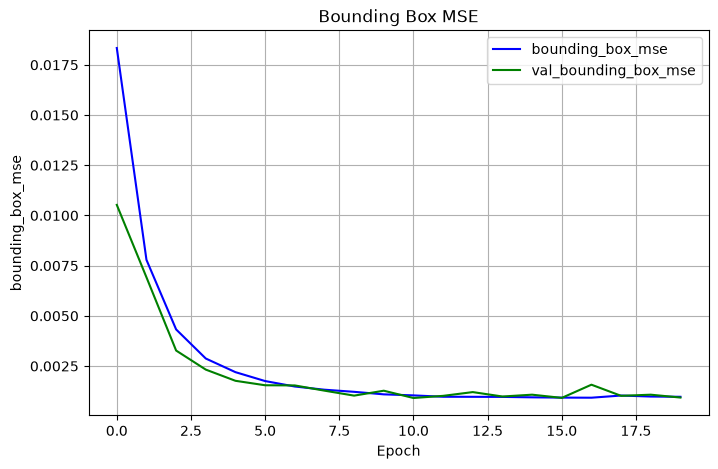

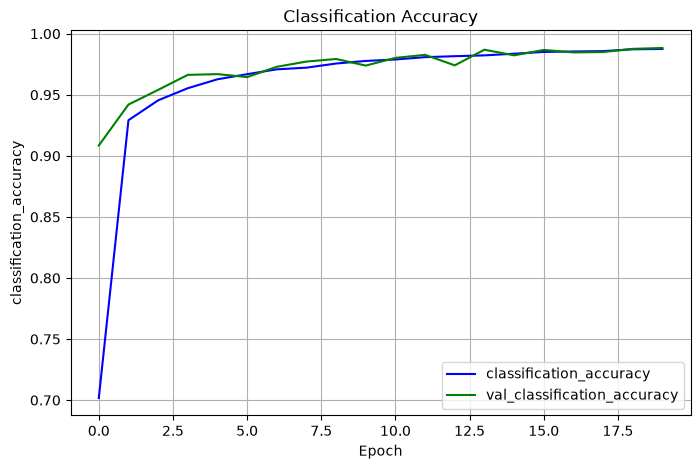

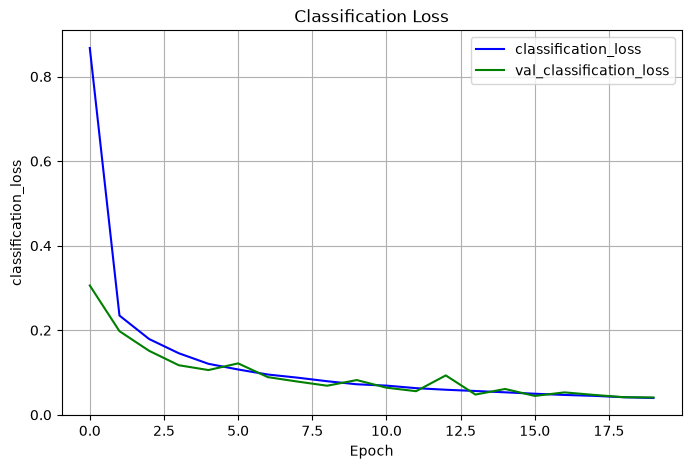

In [40]:
plot_metrics("bounding_box_mse", "Bounding Box MSE")

plot_metrics("classification_accuracy", "Classification Accuracy")

plot_metrics("classification_loss", "Classification Loss")

In [41]:
def intersection_over_union(pred_box, true_box):

    xmin_pred, ymin_pred, xmax_pred, ymax_pred = np.split(pred_box, 4, axis=1)

    xmin_true, ymin_true, xmax_true, ymax_true = np.split(true_box, 4, axis=1)

    smoothing_factor = 1e-10

    xmin_overlap = np.maximum(xmin_pred, xmin_true)
    xmax_overlap = np.minimum(xmax_pred, xmax_true)

    ymin_overlap = np.maximum(ymin_pred, ymin_true)
    ymax_overlap = np.minimum(ymax_pred, ymax_true)

    pred_box_area = (xmax_pred - xmin_pred) * (ymax_pred - ymin_pred)

    true_box_area = (xmax_true - xmin_true) * (ymax_true - ymin_true)

    overlap_area = (
        np.maximum(xmax_overlap - xmin_overlap, 0)
        * np.maximum(ymax_overlap - ymin_overlap, 0)
    )

    union_area = (
        pred_box_area
        + true_box_area
        - overlap_area
    )

    iou = (
        overlap_area + smoothing_factor
    ) / (
        union_area + smoothing_factor
    )

    return iou

In [42]:
prediction = model.predict(
    validation_digits,
    batch_size=64
)

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


In [43]:
predicted_labels = np.argmax(
    prediction[0],
    axis=1
)

prediction_bboxes = prediction[1]

In [44]:
iou = intersection_over_union(
    prediction_bboxes,
    validation_bboxes
)

In [45]:
iou_threshold = 0.6

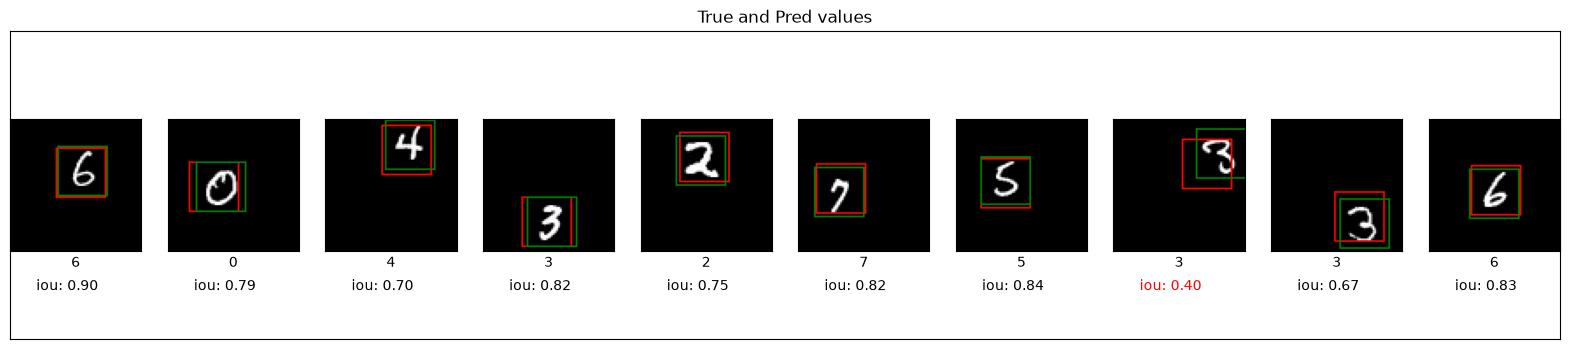

In [46]:
display_digits_with_boxes(
    validation_digits,
    predicted_labels,
    validation_labels,
    prediction_bboxes,
    validation_bboxes,
    iou,
    "True and Pred values"
)

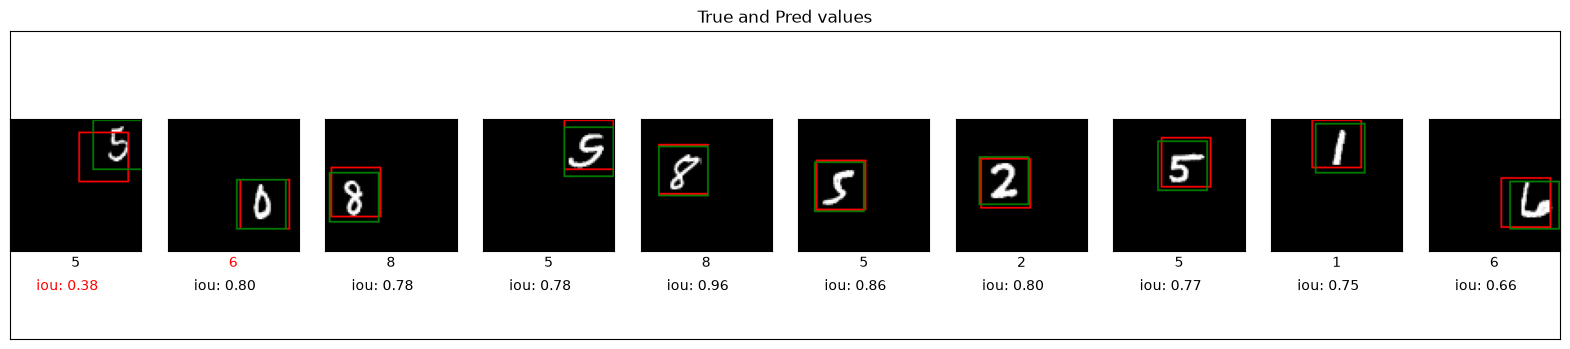

In [47]:
display_digits_with_boxes(
    validation_digits,
    predicted_labels,
    validation_labels,
    prediction_bboxes,
    validation_bboxes,
    iou,
    "True and Pred values"
)

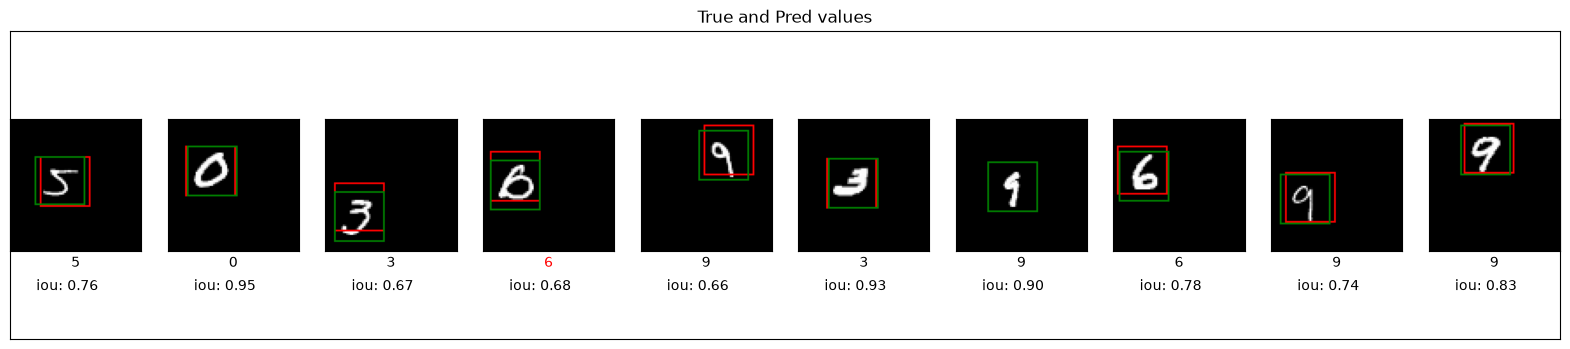

In [48]:
display_digits_with_boxes(
    validation_digits,
    predicted_labels,
    validation_labels,
    prediction_bboxes,
    validation_bboxes,
    iou,
    "True and Pred values"
)

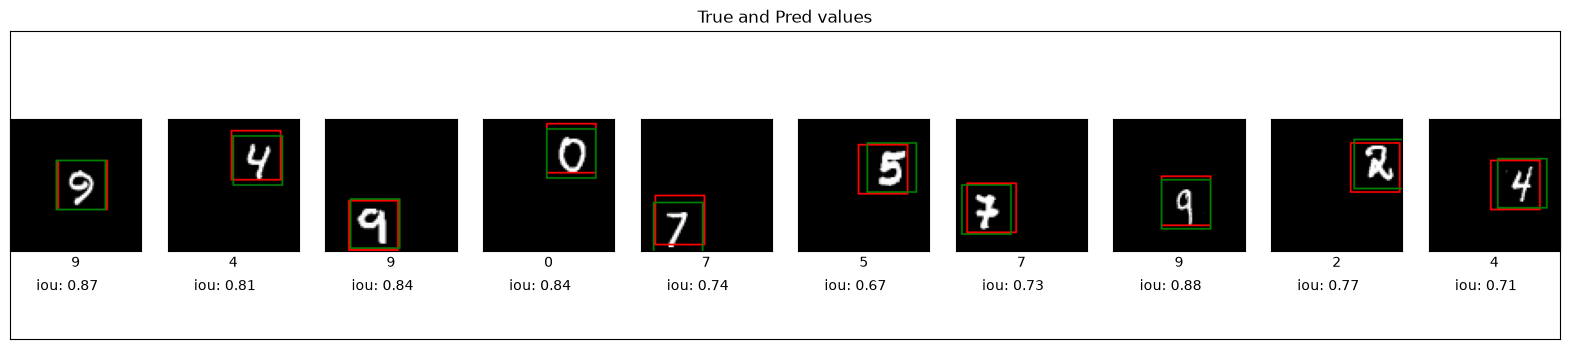

In [49]:
display_digits_with_boxes(
    validation_digits,
    predicted_labels,
    validation_labels,
    prediction_bboxes,
    validation_bboxes,
    iou,
    "True and Pred values"
)

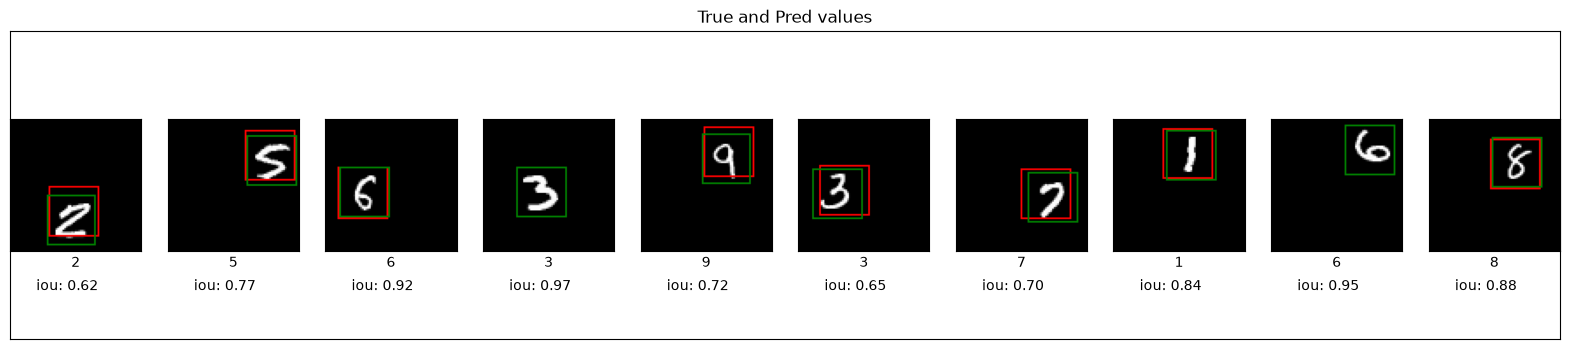

In [50]:
display_digits_with_boxes(
    validation_digits,
    predicted_labels,
    validation_labels,
    prediction_bboxes,
    validation_bboxes,
    iou,
    "True and Pred values"
)

In [53]:
model.save("digit_object_detector.keras")

In [55]:
model.save("digit_object_detector.keras")

In [56]:
model = tf.keras.models.load_model("digit_object_detector.keras")

In [57]:
import os
print(os.path.exists("digit_object_detector.keras"))

True
